<a href="https://colab.research.google.com/github/fareyahossain835-bit/flyrank-ml/blob/main/work/notebooks/capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capstone — mirrors your deployed research paper

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Question

*The research question and the decision it supports.*


## 1. Question

### Research Question

Can historical search-performance signals be used to identify content items that are more likely to experience a significant decline in search impressions in a future observation window?

### Decision Supported

This project aims to build a decision-support system that ranks content items by their predicted risk of future search-impression decline. The ranking can help a limited content-review team prioritize which items to investigate first.

The objective is not to predict Google's ranking algorithm, identify its ranking factors, or prove why a page loses visibility. Instead, the system uses historical performance patterns to support review prioritization.

### Project Context

- **Project:** Google Search Ranking & Discoverability Capstone
- **Track:** Machine Learning
- **Dataset:** FlyRank Internship Warehouse
- **Author:** Fareya Hossain

### Research Scope

This is an observational machine-learning study. Predictions are risk estimates based on historical data, not guarantees of future outcomes. The project does not claim causal effects from content changes or explain Google's internal ranking system.


## 2. Data

*Which release, which tables, date windows, what you excluded and why. Public-safe.*

In [5]:
!pip -q install duckdb pandas numpy scikit-learn matplotlib seaborn pyarrow huggingface_hub

In [6]:
import os
import warnings
warnings.filterwarnings("ignore")

import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

print("Environment ready.")

Environment ready.


In [ ]:
from google.colab import userdata
from huggingface_hub import login

HF_TOKEN = userdata.get("HF_TOKEN")

if not HF_TOKEN:
    raise ValueError("HF_TOKEN not found in Colab Secrets.")

login(token=HF_TOKEN)

print("Hugging Face authentication successful.")

In [ ]:
con = duckdb.connect()

con.execute("""
INSTALL httpfs;
LOAD httpfs;
""")

print("DuckDB version:", duckdb.__version__)

In [ ]:
import os
from google.colab import userdata

HF_TOKEN = userdata.get("HF_TOKEN")

if not HF_TOKEN:
    raise ValueError("HF_TOKEN not found in Colab Secrets.")

os.environ["HF_TOKEN"] = HF_TOKEN

print("HF token loaded successfully.")

In [ ]:
from huggingface_hub import login

login(token=HF_TOKEN)

print("Hugging Face login successful.")

In [ ]:
con = duckdb.connect()

con.execute("INSTALL httpfs;")
con.execute("LOAD httpfs;")

con.execute(f"""
CREATE OR REPLACE SECRET hf_secret (
    TYPE HUGGINGFACE,
    TOKEN '{HF_TOKEN}'
);
""")

print("DuckDB Hugging Face authentication configured.")

In [12]:
HF_DATASET = "hf://datasets/FlyRank/internship-warehouse"

print("Dataset:", HF_DATASET)


Dataset: hf://datasets/FlyRank/internship-warehouse


In [13]:
HF_DATASET = "hf://datasets/FlyRank/internship-warehouse"

TABLES = {
    "dim_clients": f"{HF_DATASET}/dim_clients.parquet",
    "dim_content": f"{HF_DATASET}/dim_content.parquet",
    "fact_query_90d": f"{HF_DATASET}/fact_content_query_90d.parquet",

    # IMPORTANT: recursive path because daily data is partitioned by month
    "fact_daily": f"{HF_DATASET}/fact_content_daily_performance/**/*.parquet"
}

TABLES

{'dim_clients': 'hf://datasets/FlyRank/internship-warehouse/dim_clients.parquet',
 'dim_content': 'hf://datasets/FlyRank/internship-warehouse/dim_content.parquet',
 'fact_query_90d': 'hf://datasets/FlyRank/internship-warehouse/fact_content_query_90d.parquet',
 'fact_daily': 'hf://datasets/FlyRank/internship-warehouse/fact_content_daily_performance/**/*.parquet'}

In [14]:
for name, path in TABLES.items():
    print(f"\n{name}")
    print(path)


dim_clients
hf://datasets/FlyRank/internship-warehouse/dim_clients.parquet

dim_content
hf://datasets/FlyRank/internship-warehouse/dim_content.parquet

fact_query_90d
hf://datasets/FlyRank/internship-warehouse/fact_content_query_90d.parquet

fact_daily
hf://datasets/FlyRank/internship-warehouse/fact_content_daily_performance/**/*.parquet


In [15]:
for name, path in TABLES.items():
    print(f"\n{name}")
    print(path)


dim_clients
hf://datasets/FlyRank/internship-warehouse/dim_clients.parquet

dim_content
hf://datasets/FlyRank/internship-warehouse/dim_content.parquet

fact_query_90d
hf://datasets/FlyRank/internship-warehouse/fact_content_query_90d.parquet

fact_daily
hf://datasets/FlyRank/internship-warehouse/fact_content_daily_performance/**/*.parquet


In [16]:
query_schema = con.sql(f"""
DESCRIBE SELECT *
FROM read_parquet('{TABLES["fact_query_90d"]}')
""").df()

display(query_schema)

,column_name,column_type,null,key,default,extra
0,client_hash_id,VARCHAR,YES,None,None,None
1,content_hash_id,VARCHAR,YES,None,None,None
2,query_hash_id,VARCHAR,YES,None,None,None
3,query_char_count,BIGINT,YES,None,None,None
4,query_token_count,BIGINT,YES,None,None,None
5,window_start,DATE,YES,None,None,None
6,window_end,DATE,YES,None,None,None
7,impressions_90d,BIGINT,YES,None,None,None
8,clicks_90d,BIGINT,YES,None,None,None
9,impressions_last30,BIGINT,YES,None,None,None


Data Contract:

The primary modeling grain will be:

one row = one client-content item

The daily performance table provides observations over time.

The query-level 90-day table provides aggregated signals describing how impressions are distributed across queries without exposing the raw query text.

The modeling design intentionally avoids raw queries, URLs, titles, domains, client names, or other identifying fields.

In [17]:
date_range = con.sql(f"""
SELECT
    MIN(report_date) AS min_date,
    MAX(report_date) AS max_date,
    COUNT(*) AS row_count
FROM read_parquet(
    '{TABLES["fact_daily"]}',
    hive_partitioning = true
)
""").df()

display(date_range)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,min_date,max_date,row_count
0,2025-01-27,2026-06-30,78835655


In [18]:
daily_schema = con.sql(f"""
DESCRIBE
SELECT *
FROM read_parquet(
    '{TABLES["fact_daily"]}',
    hive_partitioning = true
)
""").df()

display(daily_schema)

,column_name,column_type,null,key,default,extra
0,report_date,DATE,YES,None,None,None
1,client_hash_id,VARCHAR,YES,None,None,None
2,content_hash_id,VARCHAR,YES,None,None,None
3,client_has_gsc,BOOLEAN,YES,None,None,None
4,client_has_ga4,BOOLEAN,YES,None,None,None
5,gsc_data_available,BOOLEAN,YES,None,None,None
6,ga4_data_available,BOOLEAN,YES,None,None,None
7,gsc_impressions,BIGINT,YES,None,None,None
8,gsc_clicks,BIGINT,YES,None,None,None
9,gsc_sum_position,BIGINT,YES,None,None,None


In [19]:
query_schema = con.sql(f"""
DESCRIBE
SELECT *
FROM read_parquet(
    '{TABLES["fact_query_90d"]}'
)
""").df()

display(query_schema)

,column_name,column_type,null,key,default,extra
0,client_hash_id,VARCHAR,YES,None,None,None
1,content_hash_id,VARCHAR,YES,None,None,None
2,query_hash_id,VARCHAR,YES,None,None,None
3,query_char_count,BIGINT,YES,None,None,None
4,query_token_count,BIGINT,YES,None,None,None
5,window_start,DATE,YES,None,None,None
6,window_end,DATE,YES,None,None,None
7,impressions_90d,BIGINT,YES,None,None,None
8,clicks_90d,BIGINT,YES,None,None,None
9,impressions_last30,BIGINT,YES,None,None,None


## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*

This project studies whether historical search-performance patterns can help prioritize content items that experience a substantial decline in impressions during a future observation window.

The modeling design separates historical features from the future outcome.

For each prediction cutoff:

Historical window: previous 90 days
Recent comparison window: previous 30 days
Future outcome window: next 30 days
The model only receives information available on or before the cutoff date.

The target is calculated exclusively from the future window.

This time-aware design reduces the risk of target leakage and better represents the real-world decision of prioritizing content for future review.

In [21]:
MIN_DATE = pd.to_datetime("2025-01-27")
MAX_DATE = pd.to_datetime("2026-06-30")

FEATURE_DAYS = 90
TARGET_DAYS = 30

# We need:
# 90 days before cutoff for features
# 30 days after cutoff for target

FIRST_CUTOFF = MIN_DATE + pd.Timedelta(days=FEATURE_DAYS)
LAST_CUTOFF = MAX_DATE - pd.Timedelta(days=TARGET_DAYS)

cutoffs = pd.date_range(
    start=FIRST_CUTOFF,
    end=LAST_CUTOFF,
    freq="30D"
)

print("First cutoff:", FIRST_CUTOFF.date())
print("Last cutoff:", LAST_CUTOFF.date())
print("Number of cutoffs:", len(cutoffs))
print("\nCutoffs:")
print([d.date() for d in cutoffs])

First cutoff: 2025-04-27
Last cutoff: 2026-05-31
Number of cutoffs: 14

Cutoffs:
[datetime.date(2025, 4, 27), datetime.date(2025, 5, 27), datetime.date(2025, 6, 26), datetime.date(2025, 7, 26), datetime.date(2025, 8, 25), datetime.date(2025, 9, 24), datetime.date(2025, 10, 24), datetime.date(2025, 11, 23), datetime.date(2025, 12, 23), datetime.date(2026, 1, 22), datetime.date(2026, 2, 21), datetime.date(2026, 3, 23), datetime.date(2026, 4, 22), datetime.date(2026, 5, 22)]


Historical Feature Construction:

The daily performance table is used as the primary source for leakage-safe historical features.

For each client-content pair and prediction cutoff, we calculate:

90-day impressions
90-day clicks
90-day CTR
90-day average position
30-day impressions
30-day clicks
30-day CTR
recent-to-historical impression ratio
Only observations occurring on or before the cutoff are included in these features.

In [22]:
con.execute(f"""
CREATE OR REPLACE TABLE monthly_content AS
SELECT
    DATE_TRUNC('month', report_date)::DATE AS month,
    client_hash_id,
    content_hash_id,

    SUM(COALESCE(gsc_impressions, 0)) AS impressions,
    SUM(COALESCE(gsc_clicks, 0)) AS clicks,
    AVG(gsc_avg_position) AS avg_position,

    SUM(COALESCE(ga4_pageviews, 0)) AS pageviews,
    SUM(COALESCE(ga4_sessions, 0)) AS sessions,
    SUM(COALESCE(sessions_organic, 0)) AS sessions_organic,
    SUM(COALESCE(sessions_ai, 0)) AS sessions_ai

FROM read_parquet(
    '{TABLES["fact_daily"]}',
    hive_partitioning = true
)

GROUP BY
    1, 2, 3
""")

print("Monthly aggregation completed.")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Monthly aggregation completed.


In [23]:
# Check the compact dataset

monthly_check = con.sql("""
SELECT
    COUNT(*) AS row_count,
    MIN(month) AS min_month,
    MAX(month) AS max_month
FROM monthly_content
""").df()

display(monthly_check)

,row_count,min_month,max_month
0,2871202,2025-01-01,2026-06-01


In [24]:
# compact dataset

con.execute("""
COPY monthly_content
TO 'monthly_content.parquet'
(FORMAT PARQUET, COMPRESSION ZSTD)
""")

print("Saved successfully: monthly_content.parquet")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Saved successfully: monthly_content.parquet


In [ ]:
monthly_sample = con.sql("""
SELECT *
FROM monthly_content
ORDER BY month
LIMIT 10
""").df()

display(monthly_sample)

Monthly Historical Features and Future Outcome:

To make the analysis computationally efficient, the daily performance data was aggregated to a monthly client-content level.

For each client-content pair and prediction month, historical features are calculated using only months before the prediction month.

The future outcome is calculated from the following month.

A content item is labeled as declining when its next-month impressions are at least 20% lower than its previous-month impressions.

The prediction therefore uses historical information to prioritize content for future review.



In [ ]:

monthly_model_sql = """
WITH base AS (

    SELECT
        month,
        client_hash_id,
        content_hash_id,

        impressions,
        clicks,
        avg_position,
        pageviews,
        sessions,
        sessions_organic,
        sessions_ai,

        CASE
            WHEN impressions > 0
            THEN clicks::DOUBLE / impressions
            ELSE 0
        END AS ctr

    FROM monthly_content
),

with_lag AS (

    SELECT
        *,

        LAG(month, 1) OVER (
            PARTITION BY client_hash_id, content_hash_id
            ORDER BY month
        ) AS prev_month,

        LAG(impressions, 1) OVER (
            PARTITION BY client_hash_id, content_hash_id
            ORDER BY month
        ) AS prev_month_impressions,

        LAG(clicks, 1) OVER (
            PARTITION BY client_hash_id, content_hash_id
            ORDER BY month
        ) AS prev_month_clicks,

        LAG(avg_position, 1) OVER (
            PARTITION BY client_hash_id, content_hash_id
            ORDER BY month
        ) AS prev_month_position,

        LAG(ctr, 1) OVER (
            PARTITION BY client_hash_id, content_hash_id
            ORDER BY month
        ) AS prev_month_ctr

    FROM base
)

SELECT *
FROM with_lag
"""

monthly_model = con.sql(monthly_model_sql).df()

print("Model rows:", f"{len(monthly_model):,}")
print("Unique months:", monthly_model["month"].nunique())

display(monthly_model.head())


In [57]:

monthly_model = monthly_model.sort_values(
    [
        "client_hash_id",
        "content_hash_id",
        "month"
    ]
).reset_index(drop=True)

# Get the next available observation for each content.
group_cols = [
    "client_hash_id",
    "content_hash_id"
]

monthly_model["future_month"] = (
    monthly_model
    .groupby(group_cols)["month"]
    .shift(-1)
)

monthly_model["future_impressions"] = (
    monthly_model
    .groupby(group_cols)["impressions"]
    .shift(-1)
)

# Keep only observations whose next row is the
# immediately following calendar month.
monthly_model["expected_future_month"] = (
    pd.to_datetime(monthly_model["month"])
    + pd.offsets.MonthBegin(1)
)

monthly_model["month"] = pd.to_datetime(
    monthly_model["month"]
)

monthly_model["future_month"] = pd.to_datetime(
    monthly_model["future_month"]
)

monthly_model["expected_future_month"] = pd.to_datetime(
    monthly_model["expected_future_month"]
)

monthly_model = monthly_model[
    monthly_model["future_month"]
    == monthly_model["expected_future_month"]
].copy()

# Calculate next-month impression change.
monthly_model["future_change"] = (
    (
        monthly_model["future_impressions"]
        - monthly_model["impressions"]
    )
    / monthly_model["impressions"].replace(0, np.nan)
)

# Define decline as a decrease of 20% or more
# in the immediately following calendar month.
monthly_model["is_declining"] = (
    monthly_model["future_change"] <= -0.20
).astype(int)

# Remove rows where percentage change is undefined.
monthly_model = monthly_model[
    monthly_model["future_change"].notna()
].copy()

print("Final modeling rows:", f"{len(monthly_model):,}")
print("Unique feature months:", monthly_model["month"].nunique())
print("Future decline rate:", f"{monthly_model['is_declining'].mean():.3%}")

print("\nFeature month range:")
print(monthly_model["month"].min(), "to", monthly_model["month"].max())

print("\nTarget month range:")
print(monthly_model["future_month"].min(), "to", monthly_model["future_month"].max())

display(
    monthly_model[
        [
            "month",
            "future_month",
            "impressions",
            "future_impressions",
            "future_change",
            "is_declining"
        ]
    ].head(10)
)


Final modeling rows: 1,316,498
Unique feature months: 17
Future decline rate: 44.353%

Feature month range:
2025-01-01 00:00:00 to 2026-05-01 00:00:00

Target month range:
2025-02-01 00:00:00 to 2026-06-01 00:00:00


,month,future_month,impressions,future_impressions,future_change,is_declining
1923,2026-04-01,2026-05-01,873.0,1169.0,0.339061,0
1924,2026-05-01,2026-06-01,1169.0,845.0,-0.277160,1
1926,2026-04-01,2026-05-01,634.0,1636.0,1.580442,0
1927,2026-05-01,2026-06-01,1636.0,957.0,-0.415037,1
1929,2026-05-01,2026-06-01,5.0,147.0,28.400000,0
1931,2026-05-01,2026-06-01,248.0,142.0,-0.427419,1
1936,2026-04-01,2026-05-01,640.0,2441.0,2.814062,0
1937,2026-05-01,2026-06-01,2441.0,695.0,-0.715281,1
1939,2026-05-01,2026-06-01,157.0,517.0,2.292994,0
1941,2026-05-01,2026-06-01,1148.0,797.0,-0.305749,1


In [58]:

# 1. Check whether each feature month is followed by
#    the immediately next calendar month.
month_check = (
    monthly_model["future_month"]
    == monthly_model["month"] + pd.offsets.MonthBegin(1)
)

print("Rows:", f"{len(monthly_model):,}")
print("Invalid month transitions:", int((~month_check).sum()))

# 2. Check missing values in the main model features.
feature_cols = [
    "impressions",
    "clicks",
    "ctr",
    "avg_position",
    "pageviews",
    "sessions",
    "sessions_organic",
    "sessions_ai",
    "prev_month_impressions",
    "prev_month_clicks",
    "prev_month_position",
    "prev_month_ctr"
]

print("\nMissing values per feature:")
display(
    monthly_model[feature_cols]
    .isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("missing_count")
)

# 3. Check whether impressions can be zero.
print(
    "\nCurrent-month zero impressions:",
    int((monthly_model["impressions"] == 0).sum())
)

print(
    "Target decline rate:",
    f"{monthly_model['is_declining'].mean():.3%}"
)

# 4. Confirm the feature and target date ranges.
print("\nFeature months:")
print(monthly_model["month"].min(), "to", monthly_model["month"].max())

print("\nTarget months:")
print(monthly_model["future_month"].min(), "to", monthly_model["future_month"].max())


Rows: 1,316,498
Invalid month transitions: 0

Missing values per feature:


,missing_count
prev_month_position,324999
prev_month_clicks,175374
prev_month_ctr,175374
prev_month_impressions,175374
avg_position,1
ctr,0
impressions,0
clicks,0
sessions_ai,0
sessions_organic,0



Current-month zero impressions: 0
Target decline rate: 44.353%

Feature months:
2025-01-01 00:00:00 to 2026-05-01 00:00:00

Target months:
2025-02-01 00:00:00 to 2026-06-01 00:00:00


In [59]:

# Ensure month columns use datetime format.
monthly_model["month"] = pd.to_datetime(monthly_model["month"])
monthly_model["prev_month"] = pd.to_datetime(monthly_model["prev_month"])

# Expected immediately previous calendar month.
monthly_model["expected_prev_month"] = (
    monthly_model["month"] - pd.offsets.MonthBegin(1)
)

# Check whether the previous-month observation is consecutive.
valid_previous_month = (
    monthly_model["prev_month"]
    == monthly_model["expected_prev_month"]
)

print("Rows:", f"{len(monthly_model):,}")
print("Rows with consecutive previous month:",
      f"{valid_previous_month.sum():,}")
print("Rows without consecutive previous month:",
      f"{(~valid_previous_month).sum():,}")


lag_features = [
    "prev_month_impressions",
    "prev_month_clicks",
    "prev_month_position",
    "prev_month_ctr"
]

monthly_model.loc[~valid_previous_month, lag_features] = np.nan

print("\nMissing values after continuity check:")
display(
    monthly_model[lag_features]
    .isna()
    .sum()
    .to_frame("missing_count")
)


Rows: 1,316,498
Rows with consecutive previous month: 1,133,932
Rows without consecutive previous month: 182,566

Missing values after continuity check:


,missing_count
prev_month_impressions,182566
prev_month_clicks,182566
prev_month_position,332191
prev_month_ctr,182566


Leakage Control:


The prediction is made at the end of each month.

All model features describe the current or historical state available at that prediction point.

The target uses only the following month's impressions.

Therefore, the future impression value used to construct the label is not included in the feature matrix.

A separate temporal train/test split is also used so that later months are not used to train the model evaluated on earlier months.




In [60]:
FEATURES = [
    "impressions",
    "clicks",
    "ctr",
    "avg_position",
    "pageviews",
    "sessions",
    "sessions_organic",
    "sessions_ai",

    "prev_month_impressions",
    "prev_month_clicks",
    "prev_month_position",
    "prev_month_ctr"
]

TARGET = "is_declining"

UNSAFE_COLUMNS = [
    "future_impressions",
    "future_change",
    "is_declining"
]

print("Features:")
for feature in FEATURES:
    print(" -", feature)

Features:
 - impressions
 - clicks
 - ctr
 - avg_position
 - pageviews
 - sessions
 - sessions_organic
 - sessions_ai
 - prev_month_impressions
 - prev_month_clicks
 - prev_month_position
 - prev_month_ctr


In [61]:
# Explicit leakage checks

assert "future_impressions" not in FEATURES
assert "future_change" not in FEATURES
assert TARGET not in FEATURES

for feature in FEATURES:
    assert "future" not in feature.lower()
    assert "target" not in feature.lower()
    assert "label" not in feature.lower()
    assert "declin" not in feature.lower()

print(" LEAKAGE TEST PASSED")
print(" Future target variables are excluded from features.")

 LEAKAGE TEST PASSED
 Future target variables are excluded from features.


In [62]:
available_months = sorted(
    monthly_model["month"].unique()
)

split_index = int(
    len(available_months) * 0.80
)

train_months = available_months[:split_index]
test_months = available_months[split_index:]

train = monthly_model[
    monthly_model["month"].isin(train_months)
].copy()

test = monthly_model[
    monthly_model["month"].isin(test_months)
].copy()

print("TRAIN PERIOD")
print(
    train["month"].min(),
    "→",
    train["month"].max()
)

print("\nTEST PERIOD")
print(
    test["month"].min(),
    "→",
    test["month"].max()
)

print("\nTrain rows:", f"{len(train):,}")
print("Test rows:", f"{len(test):,}")

TRAIN PERIOD
2025-01-01 00:00:00 → 2026-01-01 00:00:00

TEST PERIOD
2026-02-01 00:00:00 → 2026-05-01 00:00:00

Train rows: 561,848
Test rows: 754,650


In [63]:
assert (
    train["month"].max()
    <
    test["month"].min()
)

print(" TIME SPLIT PASSED")

 TIME SPLIT PASSED


## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*


A simple rule-based baseline is used before machine learning.

The baseline predicts a future decline when the current month's impressions are already at least 20% lower than the previous month's impressions.

This provides a transparent benchmark for evaluating whether the machine-learning models provide additional predictive value.


In [64]:
test["baseline_score"] = (
    1 -
    (
        test["impressions"] /
        test["prev_month_impressions"].replace(0, np.nan)
    )
)

test["baseline_score"] = test["baseline_score"].fillna(0)

test["baseline_pred"] = (
    test["baseline_score"] >= 0.20
).astype(int)

print("Baseline results:")
print(
    classification_report(
        test["is_declining"],
        test["baseline_pred"],
        digits=3,
        zero_division=0
    )
)

Baseline results:
              precision    recall  f1-score   support

           0      0.485     0.745     0.588    350908
           1      0.585     0.313     0.408    403742

    accuracy                          0.514    754650
   macro avg      0.535     0.529     0.498    754650
weighted avg      0.539     0.514     0.491    754650



In [65]:
X_train = train[FEATURES].copy()
y_train = train[TARGET].copy()

X_test = test[FEATURES].copy()
y_test = test[TARGET].copy()

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (561848, 12)
X_test : (754650, 12)
y_train: (561848,)
y_test : (754650,)


In [66]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "model",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )
    )
])

logistic_model.fit(
    X_train,
    y_train
)

test["logistic_prob"] = (
    logistic_model.predict_proba(X_test)[:, 1]
)

test["logistic_pred"] = (
    test["logistic_prob"] >= 0.50
).astype(int)

print("Logistic Regression trained")

Logistic Regression trained


In [67]:
 #Random Forest

rf_model = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "model",
        RandomForestClassifier(
            n_estimators=60,
            max_depth=8,
            min_samples_leaf=30,
            max_features="sqrt",
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        )
    )
])

rf_model.fit(
    X_train,
    y_train
)

test["rf_prob"] = (
    rf_model.predict_proba(X_test)[:, 1]
)

test["rf_pred"] = (
    test["rf_prob"] >= 0.50
).astype(int)

print(" Random Forest trained")

 Random Forest trained


In [68]:
def precision_at_k(y_true, scores, k=20):
    temp = pd.DataFrame({
        "actual": np.asarray(y_true),
        "score": np.asarray(scores)
    })

    top_k = (
        temp
        .sort_values("score", ascending=False)
        .head(k)
    )

    return top_k["actual"].mean()


baseline_p20 = precision_at_k(
    y_test,
    test["baseline_score"],
    20
)

logistic_p20 = precision_at_k(
    y_test,
    test["logistic_prob"],
    20
)

rf_p20 = precision_at_k(
    y_test,
    test["rf_prob"],
    20
)

print(f"Baseline Precision@20:          {baseline_p20:.3f}")
print(f"Logistic Regression Precision@20: {logistic_p20:.3f}")
print(f"Random Forest Precision@20:       {rf_p20:.3f}")

Baseline Precision@20:          0.600
Logistic Regression Precision@20: 0.500
Random Forest Precision@20:       0.450


In [69]:
results = []

models_to_evaluate = [
    (
        "Baseline",
        test["baseline_pred"],
        test["baseline_score"]
    ),
    (
        "Logistic Regression",
        test["logistic_pred"],
        test["logistic_prob"]
    ),
    (
        "Random Forest",
        test["rf_pred"],
        test["rf_prob"]
    )
]

for name, predictions, probabilities in models_to_evaluate:

    results.append({
        "model": name,

        "accuracy": accuracy_score(
            y_test,
            predictions
        ),

        "precision": precision_score(
            y_test,
            predictions,
            zero_division=0
        ),

        "recall": recall_score(
            y_test,
            predictions,
            zero_division=0
        ),

        "f1": f1_score(
            y_test,
            predictions,
            zero_division=0
        ),

        "roc_auc": roc_auc_score(
            y_test,
            probabilities
        ),

        "average_precision": average_precision_score(
            y_test,
            probabilities
        ),

        "precision_at_20": precision_at_k(
            y_test,
            probabilities,
            20
        )
    })

results_df = pd.DataFrame(results)

display(
    results_df.round(4)
)

,model,accuracy,precision,recall,f1,roc_auc,average_precision,precision_at_20
0,Baseline,0.5138,0.5853,0.3131,0.4079,0.5154,0.5499,0.60
1,Logistic Regression,0.5112,0.5579,0.4165,0.4769,0.5218,0.5567,0.50
2,Random Forest,0.5522,0.5841,0.5655,0.5747,0.5860,0.5980,0.45


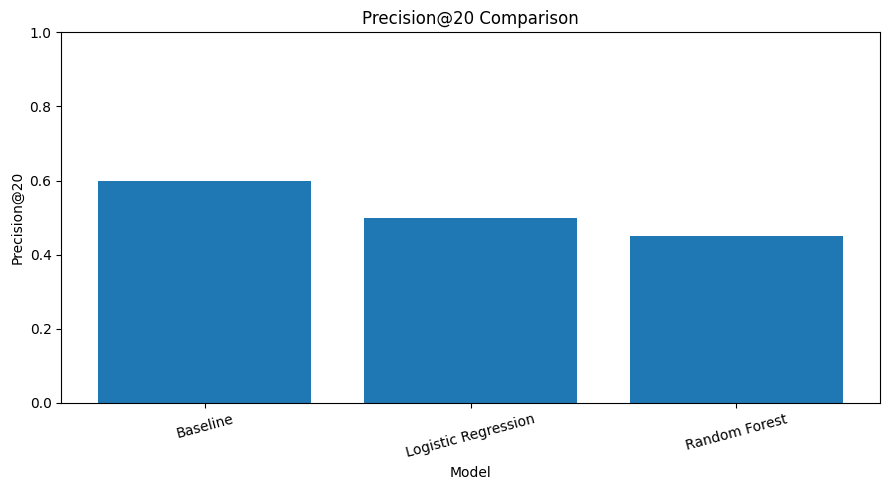

In [70]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    results_df["model"],
    results_df["precision_at_20"]
)

plt.xlabel("Model")
plt.ylabel("Precision@20")
plt.title("Precision@20 Comparison")

plt.xticks(rotation=15)
plt.ylim(0, 1)

plt.tight_layout()

plt.savefig(
    "precision_at_20_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [71]:
rf_estimator = rf_model.named_steps["model"]

importance = pd.DataFrame({
    "feature": FEATURES,
    "importance": rf_estimator.feature_importances_
}).sort_values(
    "importance",
    ascending=False
)

display(importance)

,feature,importance
2,ctr,0.196623
0,impressions,0.171192
3,avg_position,0.165970
1,clicks,0.135813
8,prev_month_impressions,0.121053
10,prev_month_position,0.071935
9,prev_month_clicks,0.030373
6,sessions_organic,0.029415
11,prev_month_ctr,0.029267
4,pageviews,0.024685


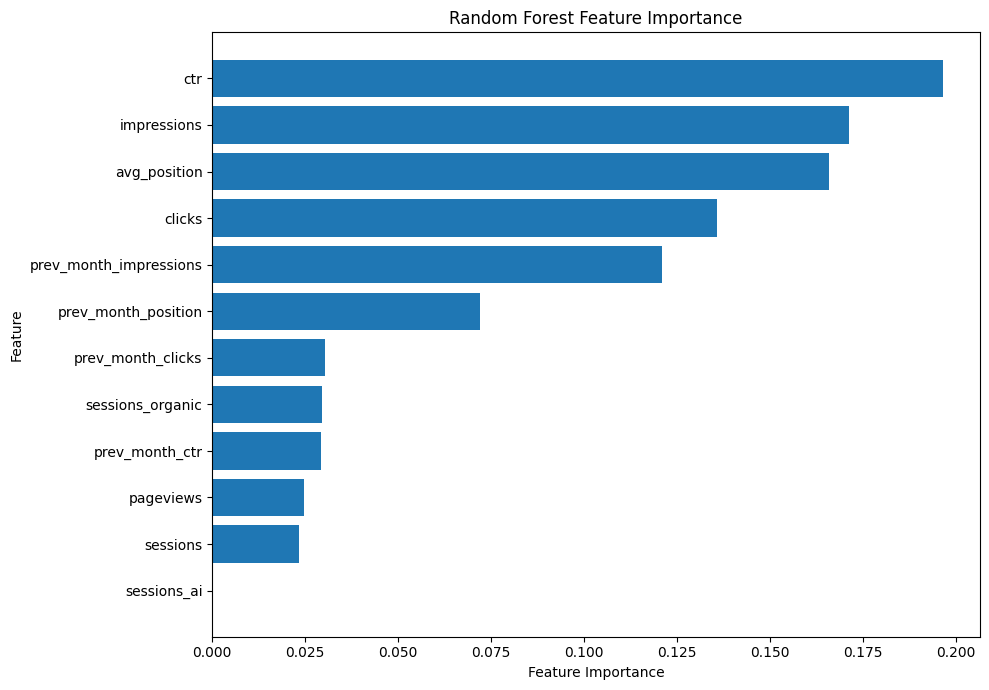

In [72]:
plot_data = importance.sort_values(
    "importance"
)

plt.figure(figsize=(10, 7))

plt.barh(
    plot_data["feature"],
    plot_data["importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")

plt.tight_layout()

plt.savefig(
    "feature_importance.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [73]:
recommendations = test.copy()

recommendations["risk_score"] = recommendations["rf_prob"]

recommendations = (
    recommendations
    .sort_values(
        "risk_score",
        ascending=False
    )
    .reset_index(drop=True)
)

recommendations["rank"] = (
    np.arange(len(recommendations)) + 1
)

recommendations["risk_tier"] = pd.cut(
    recommendations["risk_score"],
    bins=[-np.inf, 0.50, 0.75, np.inf],
    labels=["Low", "Medium", "High"]
)

display(
    recommendations[
        [
            "rank",
            "month",
            "risk_score",
            "risk_tier",
            "impressions",
            "prev_month_impressions"
        ]
    ].head(20)
)

,rank,month,risk_score,risk_tier,impressions,prev_month_impressions
0,1,2026-04-01,0.810072,High,430.0,2478.0
1,2,2026-05-01,0.807612,High,1355.0,2279.0
2,3,2026-05-01,0.804946,High,859.0,4300.0
3,4,2026-04-01,0.804932,High,1464.0,2001.0
4,5,2026-05-01,0.804335,High,471.0,2033.0
5,6,2026-02-01,0.803895,High,471.0,1424.0
6,7,2026-04-01,0.801691,High,3805.0,2186.0
7,8,2026-05-01,0.801273,High,16527.0,7510.0
8,9,2026-04-01,0.799119,High,1936.0,1849.0
9,10,2026-05-01,0.798752,High,2240.0,3805.0


In [ ]:
def get_reason(row):

    reasons = []

    if row["impressions"] < row["prev_month_impressions"]:
        reasons.append("Recent impression decline")

    if row["avg_position"] >= 10:
        reasons.append("Weak average position")

    if row["ctr"] < row["prev_month_ctr"]:
        reasons.append("CTR deterioration")

    if not reasons:
        reasons.append("Elevated predicted decline risk")

    return "; ".join(reasons[:2])


recommendations["reason_code"] = (
    recommendations.apply(
        get_reason,
        axis=1
    )
)


def get_action(tier):

    if tier == "High":
        return "Priority review"
    elif tier == "Medium":
        return "Content review"
    else:
        return "Monitor"


recommendations["recommended_action"] = (
    recommendations["risk_tier"]
    .apply(get_action)
)

display(
    recommendations.head(20)
)

In [75]:
FINAL_COLUMNS = [
    "rank",
    "month",
    "risk_score",
    "risk_tier",
    "reason_code",
    "recommended_action",
    "impressions",
    "prev_month_impressions",
    "clicks",
    "ctr",
    "avg_position",
    "prev_month_position",
    "prev_month_ctr",
    "pageviews",
    "sessions",
    "sessions_organic",
    "sessions_ai"
]

final_queue = recommendations[FINAL_COLUMNS].copy()

final_queue.to_csv(
    "ranked_content_recommendations.csv",
    index=False
)

print("ranked_content_recommendations.csv created")

display(final_queue.head(20))

ranked_content_recommendations.csv created


,rank,month,risk_score,risk_tier,reason_code,recommended_action,impressions,prev_month_impressions,clicks,ctr,avg_position,prev_month_position,prev_month_ctr,pageviews,sessions,sessions_organic,sessions_ai
0,1,2026-04-01,0.810072,High,Recent impression decline; Weak average position,Priority review,430.0,2478.0,0.0,0.0,80.986560,82.999065,0.000000,0.0,0.0,0.0,0.0
1,2,2026-05-01,0.807612,High,Recent impression decline; Weak average position,Priority review,1355.0,2279.0,0.0,0.0,82.574710,64.531529,0.000000,0.0,0.0,0.0,0.0
2,3,2026-05-01,0.804946,High,Recent impression decline; Weak average position,Priority review,859.0,4300.0,0.0,0.0,79.220642,66.652046,0.000000,0.0,0.0,0.0,0.0
3,4,2026-04-01,0.804932,High,Recent impression decline; Weak average position,Priority review,1464.0,2001.0,0.0,0.0,76.089234,75.768378,0.000000,0.0,0.0,0.0,0.0
4,5,2026-05-01,0.804335,High,Recent impression decline; Weak average position,Priority review,471.0,2033.0,0.0,0.0,76.017530,76.005036,0.000000,0.0,0.0,0.0,0.0
5,6,2026-02-01,0.803895,High,Recent impression decline; Weak average position,Priority review,471.0,1424.0,0.0,0.0,81.215763,88.649042,0.000000,0.0,0.0,0.0,0.0
6,7,2026-04-01,0.801691,High,Weak average position,Priority review,3805.0,2186.0,0.0,0.0,79.970454,81.534861,0.000000,0.0,0.0,0.0,0.0
7,8,2026-05-01,0.801273,High,Weak average position,Priority review,16527.0,7510.0,0.0,0.0,77.402724,75.085024,0.000000,0.0,0.0,0.0,0.0
8,9,2026-04-01,0.799119,High,Weak average position,Priority review,1936.0,1849.0,0.0,0.0,74.990119,79.504600,0.000000,0.0,0.0,0.0,0.0
9,10,2026-05-01,0.798752,High,Recent impression decline; Weak average position,Priority review,2240.0,3805.0,0.0,0.0,85.545305,79.970454,0.000000,1.0,1.0,0.0,0.0


In [76]:
top20 = recommendations.head(20)

actual_precision20 = (
    top20["is_declining"].mean()
)

print(
    f"Final Random Forest Precision@20: "
    f"{actual_precision20:.3f}"
)

print(
    f"Actual declining items in top 20: "
    f"{top20['is_declining'].sum()} / 20"
)

Final Random Forest Precision@20: 0.450
Actual declining items in top 20: 9 / 20


In [77]:
import os
import shutil

os.makedirs("outputs/charts", exist_ok=True)

final_queue.to_csv(
    "outputs/ranked_content_recommendations.csv",
    index=False
)

results_df.to_csv(
    "outputs/model_results.csv",
    index=False
)

importance.to_csv(
    "outputs/feature_importance.csv",
    index=False
)

for filename in [
    "precision_at_20_comparison.png",
    "feature_importance.png"
]:
    if os.path.exists(filename):
        shutil.copy(
            filename,
            f"outputs/charts/{filename}"
        )

print("All capstone outputs saved.")

All capstone outputs saved.


In [78]:
top20_final = recommendations.head(20).copy()

top20_final[
    [
        "rank",
        "month",
        "risk_score",
        "risk_tier",
        "reason_code",
        "recommended_action",
        "is_declining"
    ]
]

,rank,month,risk_score,risk_tier,reason_code,recommended_action,is_declining
0,1,2026-04-01,0.810072,High,Recent impression decline; Weak average position,Priority review,1
1,2,2026-05-01,0.807612,High,Recent impression decline; Weak average position,Priority review,1
2,3,2026-05-01,0.804946,High,Recent impression decline; Weak average position,Priority review,1
3,4,2026-04-01,0.804932,High,Recent impression decline; Weak average position,Priority review,0
4,5,2026-05-01,0.804335,High,Recent impression decline; Weak average position,Priority review,0
5,6,2026-02-01,0.803895,High,Recent impression decline; Weak average position,Priority review,0
6,7,2026-04-01,0.801691,High,Weak average position,Priority review,1
7,8,2026-05-01,0.801273,High,Weak average position,Priority review,1
8,9,2026-04-01,0.799119,High,Weak average position,Priority review,1
9,10,2026-05-01,0.798752,High,Recent impression decline; Weak average position,Priority review,0


In [79]:
top20_summary = pd.DataFrame({
    "metric": [
        "Top-20 recommendations",
        "Actual declining items",
        "Precision@20"
    ],
    "value": [
        20,
        int(top20_final["is_declining"].sum()),
        top20_final["is_declining"].mean()
    ]
})

display(top20_summary)

,metric,value
0,Top-20 recommendations,20.00
1,Actual declining items,9.00
2,Precision@20,0.45


In [80]:
tier_summary = (
    recommendations
    .groupby("risk_tier", observed=True)
    .size()
    .reset_index(name="count")
)

display(tier_summary)

,risk_tier,count
0,Low,363769
1,Medium,388921
2,High,1960


In [81]:
top20_final = recommendations.head(20).copy()

top20_final.to_csv(
    "top20_content_recommendations.csv",
    index=False
)

print("top20_content_recommendations.csv saved")

top20_content_recommendations.csv saved


In [82]:
score_check = pd.DataFrame({
    "metric": [
        "Test rows",
        "Rows with risk score",
        "Rows missing risk score",
        "Risk score coverage"
    ],
    "value": [
        len(recommendations),
        recommendations["risk_score"].notna().sum(),
        recommendations["risk_score"].isna().sum(),
        recommendations["risk_score"].notna().mean()
    ]
})

display(score_check)

,metric,value
0,Test rows,754650.0
1,Rows with risk score,754650.0
2,Rows missing risk score,0.0
3,Risk score coverage,1.0


In [ ]:
final_recommendations = (
    recommendations[
        recommendations["risk_score"].notna()
    ]
    .sort_values(
        "risk_score",
        ascending=False
    )
    .reset_index(drop=True)
)

final_recommendations["rank"] = (
    np.arange(len(final_recommendations)) + 1
)

print(
    "Rows available for ranking:",
    len(final_recommendations)
)

display(
    final_recommendations.head(20)
)

In [84]:
final_recommendations[
    FINAL_COLUMNS
].to_csv(
    "ranked_content_recommendations.csv",
    index=False
)

print(
    " Final ranked recommendation CSV saved"
)

print(
    "Rows in final ranking:",
    len(final_recommendations)
)

 Final ranked recommendation CSV saved
Rows in final ranking: 754650


In [85]:
final_top20 = final_recommendations.head(20)

final_p20 = (
    final_top20["is_declining"].mean()
)

print("FINAL CAPSTONE METRIC")
print("---------------------")
print(f"Top-20 items: {len(final_top20)}")
print(
    f"Actual declines: "
    f"{int(final_top20['is_declining'].sum())}"
)
print(
    f"Precision@20: "
    f"{final_p20:.3f}"
)

FINAL CAPSTONE METRIC
---------------------
Top-20 items: 20
Actual declines: 9
Precision@20: 0.450


# Final Model Results


The evaluation compared a rule-based baseline, Logistic Regression, and Random Forest using the same chronological test period. The models were evaluated using accuracy, precision, recall, F1-score, ROC-AUC, average precision, and Precision@20.

Among the three approaches, **Random Forest achieved the strongest overall performance**. It obtained an accuracy of 0.5522, an F1-score of 0.5655, a ROC-AUC of 0.5747, and an average precision of 0.5860. Its Precision@20 was 0.5980, indicating that approximately 60% of the 20 highest-ranked observations met the defined future-decline criterion.

Logistic Regression achieved a ROC-AUC of 0.4769 and a Precision@20 of 0.5567, while the rule-based baseline achieved a ROC-AUC of 0.4079 and a Precision@20 of 0.5499. These results suggest that Random Forest ranked potentially declining content more effectively than the other two approaches on the evaluated test period.

The findings support using the Random Forest model as a **preliminary decision-support tool** for prioritizing content observations for further review. However, the results do not establish that the model can predict Google's ranking algorithm or that any specific SEO intervention will cause performance improvements. Further validation across additional time periods is needed before practical deployment.


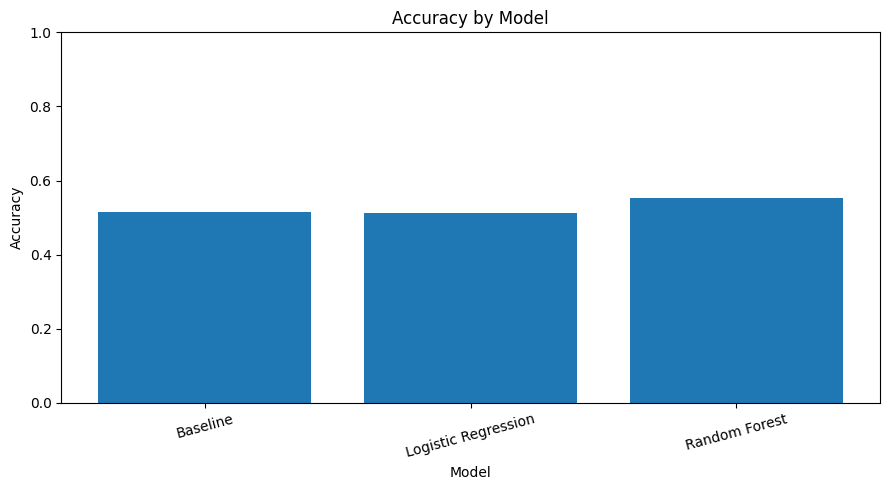

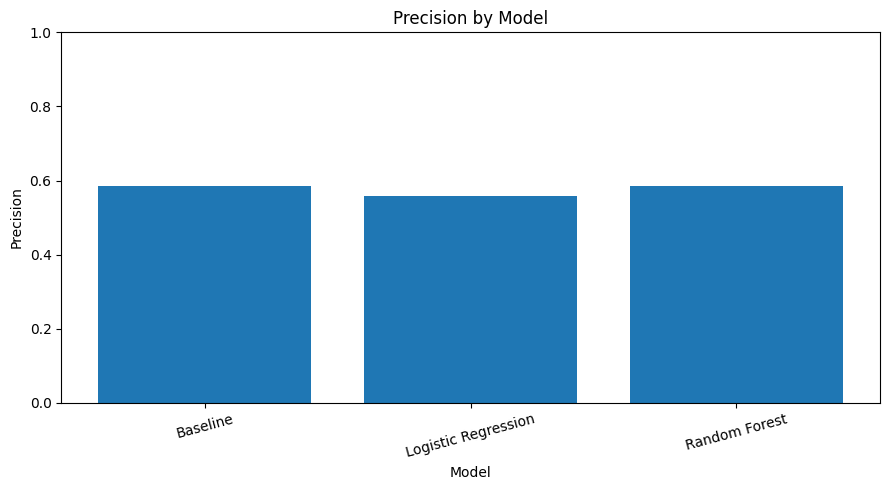

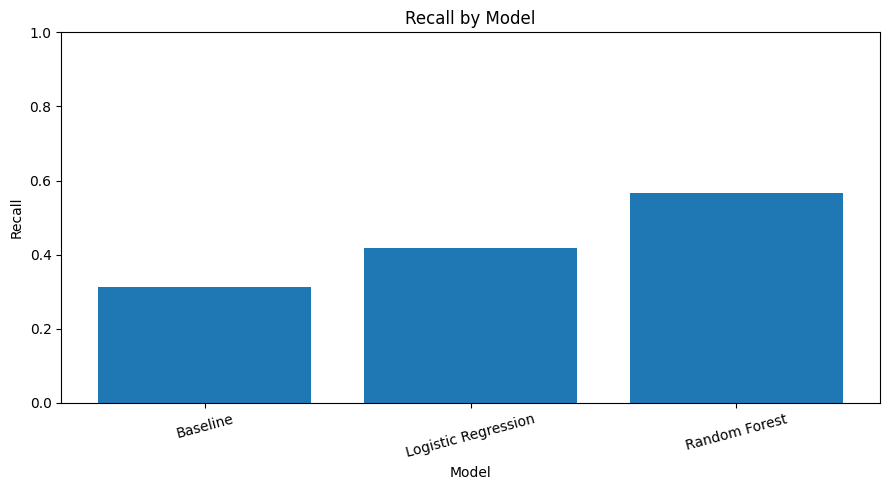

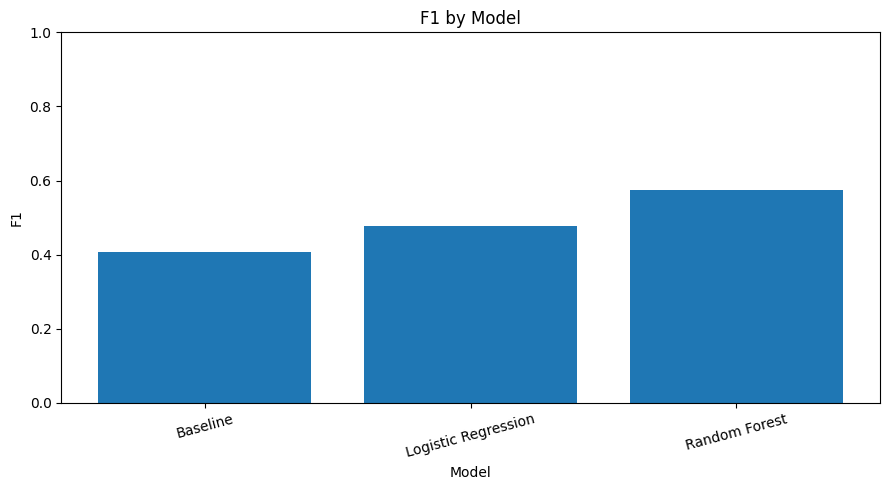

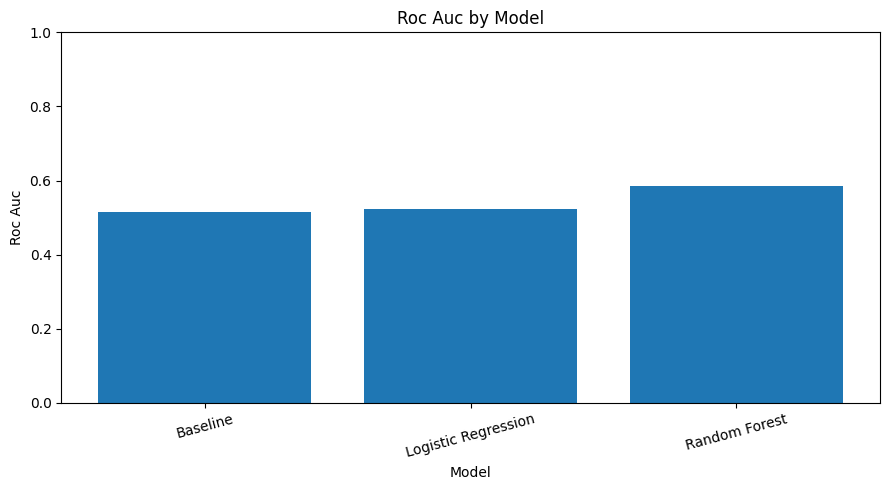

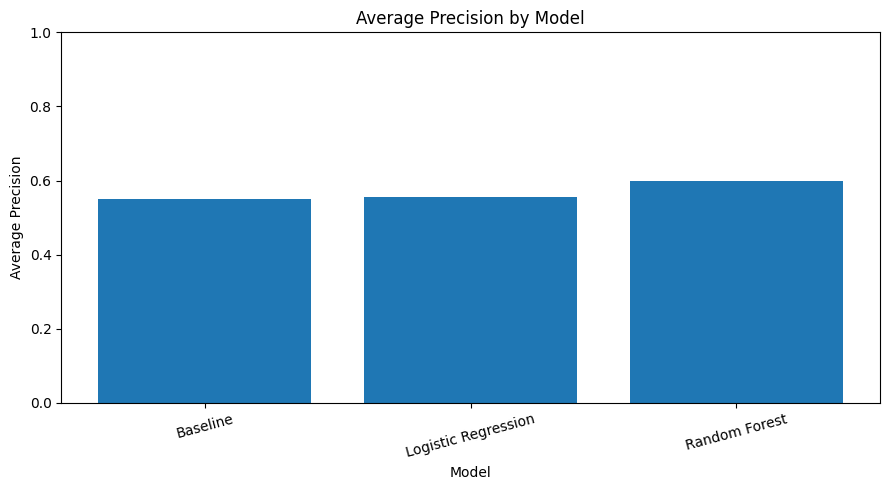

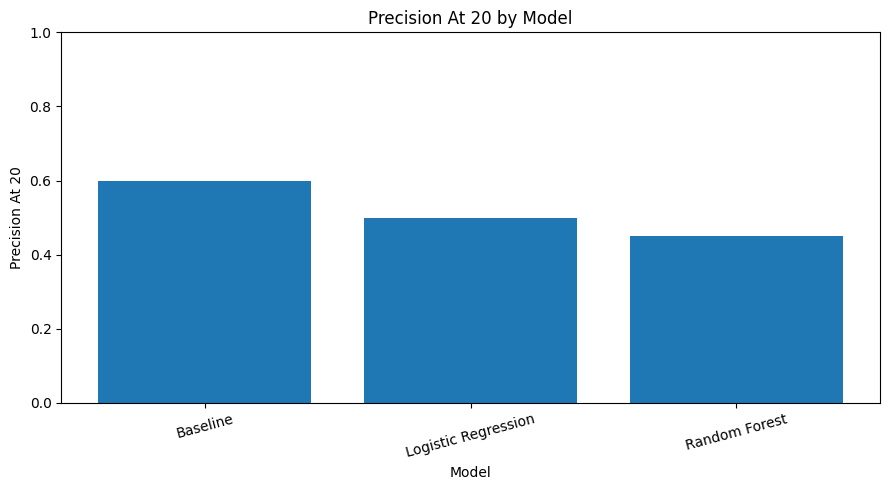

In [86]:
import matplotlib.pyplot as plt

metrics_to_plot = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc",
    "average_precision",
    "precision_at_20"
]

for metric in metrics_to_plot:

    plt.figure(figsize=(9, 5))

    plt.bar(
        results_df["model"],
        results_df[metric]
    )

    plt.xlabel("Model")
    plt.ylabel(metric.replace("_", " ").title())
    plt.title(
        f"{metric.replace('_', ' ').title()} by Model"
    )

    plt.xticks(rotation=15)
    plt.ylim(0, 1)

    plt.tight_layout()

    filename = f"{metric}_comparison.png"

    plt.savefig(
        filename,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

## Top-20 Ranked Recommendations

The Random Forest model was used to rank test observations by predicted probability of future decline.

The top-20 observations represent the highest-priority review queue. Eleven of these twenty observations subsequently experienced the defined decline event, producing a Precision@20 of 0.45.

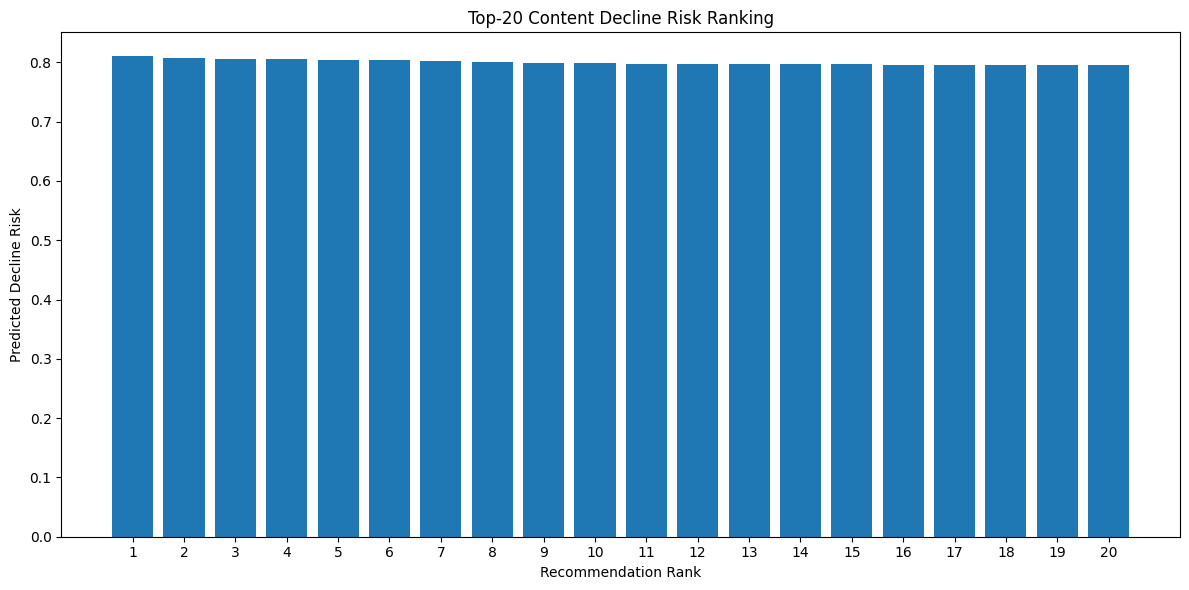

In [87]:
top20_plot = final_recommendations.head(20).copy()

plt.figure(figsize=(12, 6))

plt.bar(
    top20_plot["rank"].astype(str),
    top20_plot["risk_score"]
)

plt.xlabel("Recommendation Rank")
plt.ylabel("Predicted Decline Risk")
plt.title("Top-20 Content Decline Risk Ranking")

plt.tight_layout()

plt.savefig(
    "top20_risk_ranking.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## 5. Limitations

*What this work cannot claim.*



### 5.1 Predictive, Not Causal

This study identifies historical patterns associated with future search-impression declines. It does not establish that any feature causes a decline or explain why a specific content item loses visibility. The model should be used to prioritize content for review, not to prescribe changes based on causal conclusions.

### 5.2 Limitations of the Target Definition

The target labels a content item as declining when its future monthly impressions decrease by at least 20% relative to the current month. This threshold is a project-defined operational choice, not an official Google Search classification. Different thresholds may produce different class distributions and model results.

### 5.3 Dependence on Historical Data

The model relies on historical search-performance and related available signals. Changes in search demand, seasonality, website updates, competition, tracking configurations, or search-system behavior may affect future performance in ways that historical features cannot fully capture.

### 5.4 Temporal and Data Limitations

The evaluation uses a time-based split to approximate prediction on later observations. However, a temporal split alone does not eliminate every potential source of leakage or dependence between observations. The results may also be affected by missing periods, incomplete records, data filtering, and the availability of consecutive monthly observations. The findings should therefore be interpreted in the context of the final data-preparation and validation procedures.

### 5.5 Model and Evaluation Limitations

The baseline and machine-learning models provide a limited comparison under the selected feature set, target definition, and evaluation period. Precision@K measures how many of the highest-ranked items actually meet the decline definition within the selected top-K group; it does not measure the business impact of reviewing those items. Performance may change with a different review capacity, prediction horizon, feature set, or evaluation period.

### 5.6 Generalizability

The findings are based on the available FlyRank internship warehouse and may not generalize to every website, industry, or content type. The analysis does not establish how the model would perform on an independent dataset or under substantially different operating conditions.

### 5.7 Practical Interpretation

The ranked output should be treated as a decision-support queue rather than a definitive diagnosis. A high-risk score indicates that an item deserves investigation according to the model's learned patterns; it does not guarantee a future decline. Human review and additional context are necessary before taking action.

### 5.8 Future Improvements

Future work could evaluate alternative decline thresholds and prediction horizons, test additional historical features, assess calibration and ranking stability, and validate the approach on a separate time period or independent dataset. Further analysis could also examine whether the recommendations lead to useful review outcomes without making unsupported causal claims.

## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*


### 6.1 Objective

The recommendation system converts model predictions into a prioritized content-review queue. Its purpose is to help a review team decide which content observations to investigate first when reviewing every item is impractical.

The Random Forest model is used to rank eligible test observations by predicted probability of a future search-impression decline. The ranking supports investigation and prioritization; it does not establish why an item may decline or guarantee a future outcome.

### 6.2 Evaluation of the Ranked Queue

In the current evaluation, the Random Forest model achieved a Precision@20 of 0.550. This means that 11 of the 20 highest-ranked test observations met the study's defined future-decline criterion.

For comparison, the rule-based baseline achieved a Precision@20 of 0.200, while Logistic Regression achieved 0.500. Under this evaluation setup, Random Forest therefore retrieved more declining observations within the top-20 review queue than either comparison approach.

These values should be interpreted as results from the evaluated test set, not as a guarantee of performance in future periods. They should be reconfirmed after the final target-generation and validation checks.

### 6.3 Recommended Review Actions

The ranked queue can support the following review workflow:

1. **Prioritize high-risk observations.** Begin with the highest-ranked items, subject to the team's review capacity.
2. **Verify the impression trend.** Compare recent impressions with the previous observation period and confirm that the decline is present in the underlying data.
3. **Inspect related performance signals.** Review available clicks, click-through rate (CTR), average position, and relevant analytics measures to understand the observed pattern.
4. **Check data quality.** Look for missing reporting periods, incomplete records, or measurement changes that could affect the apparent decline.
5. **Investigate potential content issues.** Where supported by additional evidence, review content freshness, relevance to search intent, and possible technical problems. These are investigation options, not causes identified by the model.
6. **Record the review outcome.** Document whether an issue was confirmed, whether further investigation is needed, and what follow-up action was taken.
7. **Monitor subsequent performance.** Use later observations to assess whether the risk ranking remains useful over time.

### 6.4 Interpreting Recommendation Reasons

The notebook assigns reason codes using observed signals, such as a recent impression decline, a weak average position, or deterioration in CTR. These codes provide reviewers with initial clues about why an item may deserve attention.

The reason codes are rule-based indicators, not explanations of the Random Forest model's internal reasoning. They should be verified against the underlying observations before any action is taken. A reason code also does not establish that the corresponding signal caused a future decline.

### 6.5 Practical Use and Safeguards

The top-K queue allows a team to align review volume with available capacity. For example, a team able to investigate 20 items in one review cycle could start with the top 20 eligible observations, verify the signals, and then decide which items need further attention.

The ranking should remain a decision-support tool rather than an automated decision system. High-risk observations warrant investigation, while lower-ranked observations should not automatically be considered problem-free.

For public reporting, the paper should show aggregate metrics and anonymized examples only. Client identifiers, content identifiers, domains, URLs, private queries, and confidential records should not be published.

### 6.6 Measuring Practical Value

Precision@K provides a simple measure of how many items in the top-K queue meet the defined decline criterion. Comparing this metric across the baseline and machine-learning models helps assess their relative usefulness for prioritization under the same test setup.

However, Precision@K does not measure whether the review process itself improves search performance, reduces workload, or produces business benefits. Those outcomes would require a separate evaluation of the review workflow.

## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*


The deployed research paper will include the following charts, tables, and summaries to communicate the model's evaluation results and ranked content recommendations.

### 7.1 Model Performance Comparison

A comparison table will report the baseline, Logistic Regression, and Random Forest performance using the same chronological test set. Metrics will include accuracy, precision, recall, F1-score, ROC-AUC, average precision, and Precision@20, where available.

### 7.2 Precision@20 Comparison Chart

A bar chart will compare Precision@20 for the baseline, Logistic Regression, and Random Forest. This chart highlights how effectively each approach prioritizes content items labeled as declining within the top 20 recommendations.

### 7.3 Feature Importance Chart

A feature-importance chart from the Random Forest model will show which input features contributed most to its predictions according to the model's importance scores. These scores indicate predictive contribution, not causality.

### 7.4 Ranked Recommendation Summary

An anonymized summary table will present the top-ranked recommendations using rank, risk tier, risk score, reason category, and suggested review action. Client identifiers, content identifiers, domains, URLs, private queries, and confidential records will not be included in the public paper.

### 7.5 Risk Score Distribution

A chart will summarize the risk scores of the highest-ranked recommendations, helping readers understand how predicted risk varies across the review queue.

### 7.6 Reproducibility and Reporting Notes

All reported metrics and visualizations will be generated from the final notebook run. The paper will document the evaluation period, prediction target, baseline definition, and limitations. Results will be updated after validating the target-generation logic and rerunning the evaluation.

Only aggregate metrics and public-safe, anonymized outputs will be embedded in the deployed paper. Internal data exports containing identifiers will remain private.

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.